In [1]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)

from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson
import scanpy as sc
import os
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import scipy.sparse as sp
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())


/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1


In [2]:
def check_nan(adata, name):
    X = adata.X

    if sp.issparse(X):
        nan_count = np.isnan(X.data).sum()
    else:
        nan_count = np.isnan(X).sum()

    print(f"{name} NaN count:", nan_count)

real_data: View of AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
r2,pearsonr: 0.9488297049787697 0.9744422212561044
5.569802292682582 4.8702583
5.569802292682582 4.8702583
max 5.569802292682582


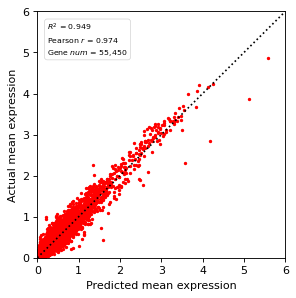

In [3]:

real_data_origin = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
real_data = real_data_origin[real_data_origin.obs['Group']==19]
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_18_1_percent/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
predict_data.X = predict_data.X.astype(np.float64)
# check_nan(predict_data, "predict_data")
# check_nan(real_data, "real_data")
# if isinstance(predict_data, anndata.AnnData):
#     print("a")
#     x_np = predict_data.X
#     print(x_np)
#     print(x_np.mean(axis=0))
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(predict,
            real,
            s=4,
            c='red'
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 1)
else:    
  ticks = np.arange(0, limit + 1, 100)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
plt.xlabel(f"Predicted mean expression")
plt.ylabel(f"Actual mean expression")
ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson $r$ = {pearsonr:.3f}\nGene $num$ = {len(predict):,}",
      transform=ax.transAxes, va="top", ha="left", fontsize=7, linespacing=1.4,
      bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
fig.savefig(os.path.join(f"day7_day10_predict_day19_18_1_percent.pdf"), bbox_inches="tight")


real_data: View of AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
r2,pearsonr: 0.9610881335507405 0.9867351967630034
4.775421039549066 4.8702583
4.775421039549066 4.8702583
max 4.8702583


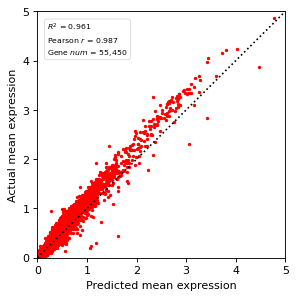

In [4]:

real_data_origin = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
real_data = real_data_origin[real_data_origin.obs['Group']==19]
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_18_10_percent/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
predict_data.X = predict_data.X.astype(np.float64)
# check_nan(predict_data, "predict_data")
# check_nan(real_data, "real_data")
# if isinstance(predict_data, anndata.AnnData):
#     print("a")
#     x_np = predict_data.X
#     print(x_np)
#     print(x_np.mean(axis=0))
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(predict,
            real,
            s=4,
            c='red'
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 1)
else:    
  ticks = np.arange(0, limit + 1, 100)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
plt.xlabel(f"Predicted mean expression")
plt.ylabel(f"Actual mean expression")
ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson $r$ = {pearsonr:.3f}\nGene $num$ = {len(predict):,}",
      transform=ax.transAxes, va="top", ha="left", fontsize=7, linespacing=1.4,
      bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
fig.savefig(os.path.join(f"day7_day10_predict_day19_18_10_percent.pdf"), bbox_inches="tight")


real_data: View of AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
r2,pearsonr: 0.9712769623477628 0.9877728672961542
5.1374500016968305 4.8702583
5.1374500016968305 4.8702583
max 5.1374500016968305


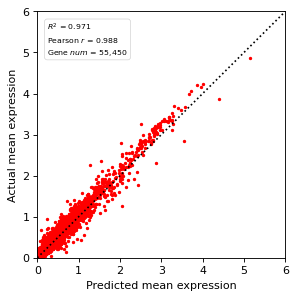

In [5]:

real_data_origin = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
real_data = real_data_origin[real_data_origin.obs['Group']==19]
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_18_25_percent/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
predict_data.X = predict_data.X.astype(np.float64)
# check_nan(predict_data, "predict_data")
# check_nan(real_data, "real_data")
# if isinstance(predict_data, anndata.AnnData):
#     print("a")
#     x_np = predict_data.X
#     print(x_np)
#     print(x_np.mean(axis=0))
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(predict,
            real,
            s=4,
            c='red'
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 1)
else:    
  ticks = np.arange(0, limit + 1, 100)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
plt.xlabel(f"Predicted mean expression")
plt.ylabel(f"Actual mean expression")
ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson $r$ = {pearsonr:.3f}\nGene $num$ = {len(predict):,}",
      transform=ax.transAxes, va="top", ha="left", fontsize=7, linespacing=1.4,
      bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
fig.savefig(os.path.join(f"day7_day10_predict_day19_18_25_percent.pdf"), bbox_inches="tight")


real_data: View of AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
r2,pearsonr: 0.9657309263474221 0.9849912473071414
5.112550019365182 4.8702583
5.112550019365182 4.8702583
max 5.112550019365182


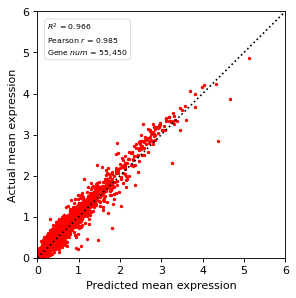

In [6]:

real_data_origin = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
real_data = real_data_origin[real_data_origin.obs['Group']==19]
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_18_50_percent/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
predict_data.X = predict_data.X.astype(np.float64)
# check_nan(predict_data, "predict_data")
# check_nan(real_data, "real_data")
# if isinstance(predict_data, anndata.AnnData):
#     print("a")
#     x_np = predict_data.X
#     print(x_np)
#     print(x_np.mean(axis=0))
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(predict,
            real,
            s=4,
            c='red'
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 1)
else:    
  ticks = np.arange(0, limit + 1, 100)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
plt.xlabel(f"Predicted mean expression")
plt.ylabel(f"Actual mean expression")
ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson $r$ = {pearsonr:.3f}\nGene $num$ = {len(predict):,}",
      transform=ax.transAxes, va="top", ha="left", fontsize=7, linespacing=1.4,
      bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
fig.savefig(os.path.join(f"day7_day10_predict_day19_18_50_percent.pdf"), bbox_inches="tight")


real_data: View of AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
r2,pearsonr: 0.9764630022420135 0.989250967522475
4.728633035901662 4.8702583
4.728633035901662 4.8702583
max 4.8702583


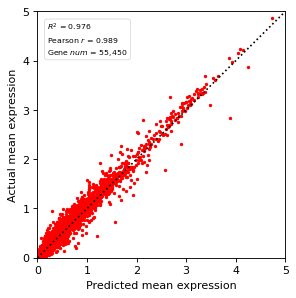

In [7]:

real_data_origin = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
real_data = real_data_origin[real_data_origin.obs['Group']==19]
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_18_70_percent/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
predict_data.X = predict_data.X.astype(np.float64)
# check_nan(predict_data, "predict_data")
# check_nan(real_data, "real_data")
# if isinstance(predict_data, anndata.AnnData):
#     print("a")
#     x_np = predict_data.X
#     print(x_np)
#     print(x_np.mean(axis=0))
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(predict,
            real,
            s=4,
            c='red'
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 1)
else:    
  ticks = np.arange(0, limit + 1, 100)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
plt.xlabel(f"Predicted mean expression")
plt.ylabel(f"Actual mean expression")
ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson $r$ = {pearsonr:.3f}\nGene $num$ = {len(predict):,}",
      transform=ax.transAxes, va="top", ha="left", fontsize=7, linespacing=1.4,
      bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
fig.savefig(os.path.join(f"day7_day10_predict_day19_18_70_percent.pdf"), bbox_inches="tight")

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


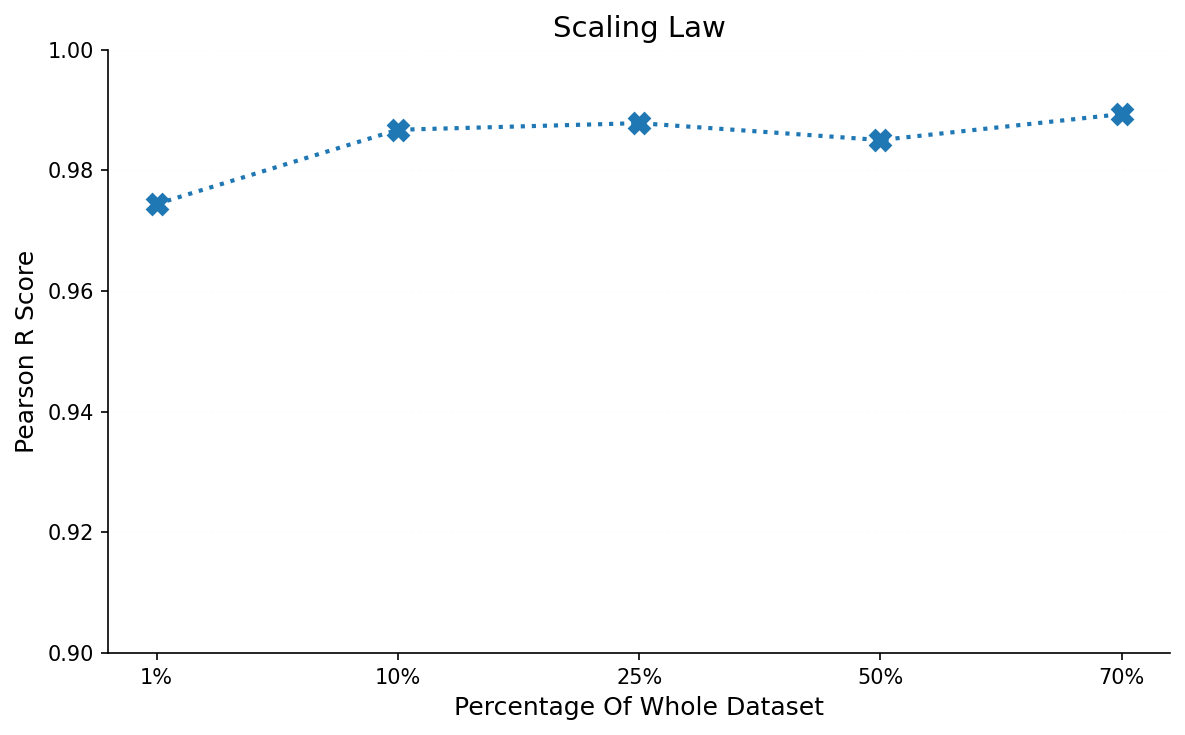

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# Example benchmark data
# Replace these values with your own results
# --------------------------------------------------

x = ["1%","10%","25%","50%","70%"]
pearsonr = [0.9744,0.9867,0.9878,0.9850,0.9893]

fig, ax = plt.subplots(figsize=(8, 5), dpi=150)

ax.plot(
    x,
    pearsonr,
    marker="X",
    markersize=10,
    markeredgewidth=1.3,
    linestyle=":",
    linewidth=2
)


ax.set_xlabel("Percentage Of Whole Dataset", fontsize=12)
ax.set_ylabel("Pearson R Score", fontsize=12)
ax.set_title("Scaling Law", fontsize=14)

ax.legend(frameon=False)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.02
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_ylim(0.9, 1.0)
plt.tight_layout()
fig.savefig(os.path.join(f"scaling_law_pearsonr.pdf"), bbox_inches="tight")
# plt.show()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


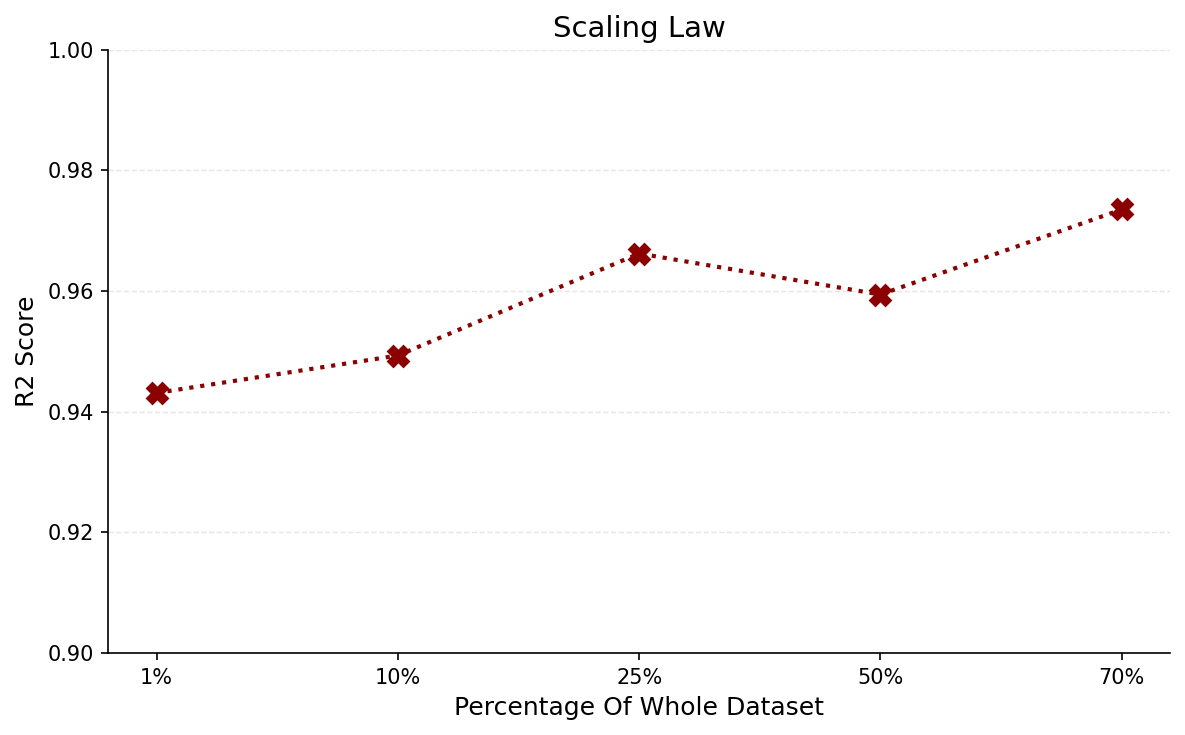

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# Example benchmark data
# Replace these values with your own results
# --------------------------------------------------

x = ["1%","10%","25%","50%","70%"]
r2 =[0.9431,0.9493,0.9662,0.9594,0.9735]

fig, ax = plt.subplots(figsize=(8, 5), dpi=150)


ax.plot(
    x,
    r2,
    marker="X",
    markersize=10,
    markeredgewidth=1.3,
    linestyle=":",
    linewidth=2,
    color="darkred"
)

ax.set_xlabel("Percentage Of Whole Dataset", fontsize=12)
ax.set_ylabel("R2 Score", fontsize=12)
ax.set_title("Scaling Law", fontsize=14)

ax.legend(frameon=False)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.3
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_ylim(0.9, 1.0)

plt.tight_layout()
fig.savefig(os.path.join(f"scaling_law_r2.pdf"), bbox_inches="tight")
# plt.show()

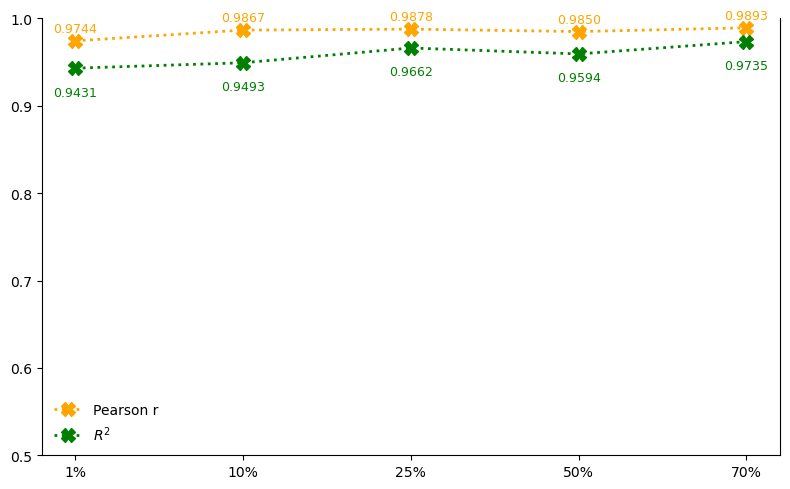

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    x,
    pearsonr,
    marker="X",
    markersize=10,
    linestyle=":",
    linewidth=2,
    color="orange",
    label="Pearson r"
)

ax.plot(
    x,
    r2,
    marker="X",
    markersize=10,
    linestyle=":",
    linewidth=2,
    color="green",
    label=r"$R^2$"
)

# Add numbers above Pearson r points
for i, value in enumerate(pearsonr):
    ax.text(
        i,
        value + 0.01,
        f"{value:.4f}",
        ha="center",
        fontsize=9,
        color="orange"
    )

# Add numbers below R² points
for i, value in enumerate(r2):
    ax.text(
        i,
        value - 0.02,
        f"{value:.4f}",
        ha="center",
        va="top",
        fontsize=9,
        color="green"
    )

ax.set_ylim(0.5, 1.0)
ax.spines["top"].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()
fig.savefig(os.path.join(f"scaling_law_all.pdf"), bbox_inches="tight")